# **LAB01: ÔN TẬP CÁC THƯ VIỆN**



# **Cài đặt và chuẩn bị môi trường**

## **Cài đặt các thư viện cần thiết**

In [2]:
%pip install -U numpy pandas matplotlib seaborn scipy scikit-learn ucimlrepo

Note: you may need to restart the kernel to use updated packages.


## **Import các thư viện, kiểm tra phiên bản**

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
import ucimlrepo

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)
print("Scipy version:",  scipy .__version__)
print("Seaborn version:", sns.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("ucimlrepo: OK")

NumPy version: 2.5.3
Pandas version: 3.0.6
Matplotlib version: 3.11.2
Scipy version: 1.18.1
Seaborn version: 0.13.2
Scikit-learn version: 1.9.1
ucimlrepo: OK


# **1. Thư viện NumPy**



## **1.1. Cú pháp cơ bản. Khởi tạo mảng**

In [4]:
# Ví dụ cách tạo ma trận
x = np.array([
    [1, 2],
    [3, 4],
    [5, 6],
    [7, 8]
])
y = np.array([0, 1, 1, 0])
print("x= ", x)

print("y = ",y)

# Thông tin của x:
print("x.shape", x.shape)
print("x.ndim", x.ndim)
print("x.dtype", x.dtype)
print("n_sample", x.shape[0])
print("n_features", x.shape[1])
print("n_classes", len(np.unique(y)))

x=  [[1 2]
 [3 4]
 [5 6]
 [7 8]]
y =  [0 1 1 0]
x.shape (4, 2)
x.ndim 2
x.dtype int64
n_sample 4
n_features 2
n_classes 2



### **Bài tập 1.1:**

In [5]:
x1 = np.array([
    [1, 2, 3],
    [4, 5 , 6],
    [7, 8, 9],
    [10, 11, 12],
    [13, 14, 15],
    [16, 17, 18]
])


y1 = np.array([1, 2, 3, 1, 2, 3, 3])

print("x1.shape", x1.shape)
print("x1.ndim", x1.ndim)
print("x1.dtype", x1.dtype)
print("max", np.max(x1, axis = 0))
print("min", np.min(x1, axis = 0))
print("Classes:", len(np.unique(y1)))
print("unique", np.unique(y1))

rng = np.random.default_rng(42) 
random_matrix_float = rng.random((3, 3))
random_matrix_int = rng.integers(low=0, high=10, size=(2, 2))
print("Matrix (3x3):\n", random_matrix_float)
print("Matrix (2x2):\n", random_matrix_int)

x1.shape (6, 3)
x1.ndim 2
x1.dtype int64
max [16 17 18]
min [1 2 3]
Classes: 3
unique [1 2 3]
Matrix (3x3):
 [[0.77395605 0.43887844 0.85859792]
 [0.69736803 0.09417735 0.97562235]
 [0.7611397  0.78606431 0.12811363]]
Matrix (2x2):
 [[8 4]
 [5 3]]


## **1.2. Các hàm khởi tạo đặc biệt**


* `np.arange(start, stop, step)`: Tạo mảng với bước nhảy đều.
* `np.linspace(start, stop, num)`: Tạo mảng gồm các điểm chia đều trong đoạn $[start, stop]$.
* `np.zeros(shape)` / `np.ones(shape)`: Khởi tạo mảng chứa toàn bộ giá trị 0 hoặc 1.
* `np.random.default_rng()`: Bộ sinh số ngẫu nhiên hiện đại (thay thế cách gọi cũ `np.random.seed`).

In [6]:
a = np.array([1, 2, 3, 4])
b = np.arange(4, 1, 2)
c = np.linspace(0, 1, 5)
zeros = np.zeros((2, 3))
rng = np.random.default_rng(42)

print("a = ", a)
print("b = ", b)
print("c = ", c)
print("zeros =\n ", zeros)
print("random =\n ", rng)


a =  [1 2 3 4]
b =  []
c =  [0.   0.25 0.5  0.75 1.  ]
zeros =
  [[0. 0. 0.]
 [0. 0. 0.]]
random =
  Generator(PCG64)


## **1.3. Indexing, Slicing & Masking**
* **Indexing**: Truy xuất phần tử đơn lẻ theo chỉ số vị trí hàng và cột.
* **Slicing**: Trích xuất dòng đơn, cột đơn hoặc một ma trận con 
* **Masking**: Lọc dữ liệu theo điều kiện logic 

In [7]:
x3 = np.arange(20).reshape(5, 4)
print("x3 =\n", x3)
print("Dong 0:\n", x3[0])
print("Cot 1:\n", x3[:,1])
print("Khoi 2x2:\n", x3[1:3, 1:3])

# mask():
mask = x3[:,0] > 5
print("Mask:", mask)
print("Cac dong thoa dk:\n", x3[mask])

x3 =
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]
 [12 13 14 15]
 [16 17 18 19]]
Dong 0:
 [0 1 2 3]
Cot 1:
 [ 1  5  9 13 17]
Khoi 2x2:
 [[ 5  6]
 [ 9 10]]
Mask: [False False  True  True  True]
Cac dong thoa dk:
 [[ 8  9 10 11]
 [12 13 14 15]
 [16 17 18 19]]


## **1.4. Phép toán vector và Thống kê**

* **Vectorization**: Thực hiện các phép toán số học cộng, trừ, nhân, lũy thừa đồng thời trên toàn bộ mảng mà không cần dùng vòng lặp `for`.
* **Thống kê**: Tính giá trị trung bình (`mean`), độ lệch chuẩn (`std`), nhỏ nhất (`min`), lớn nhất (`max`).

In [8]:
x4 = np.arange(6)

print("x4 = ", x4)
print("x4 + 10 = ", x4 + 1)
print("x4 * 2 = ", x4 * 2)
print("x4^3 =", x4 **3)

#Cac cu phap thong thong ke
print("mean:", x4.mean())
print("std:", x4.std())
print("min:", x4.min())
print("max:", x4.max())

x4 =  [0 1 2 3 4 5]
x4 + 10 =  [1 2 3 4 5 6]
x4 * 2 =  [ 0  2  4  6  8 10]
x4^3 = [  0   1   8  27  64 125]
mean: 2.5
std: 1.707825127659933
min: 0
max: 5


## **1.5. Tính toán ma trận**
* **Phép nhân ma trận**: Toán tử `@` hoặc hàm `np.matmul(A, B)` 
* **Chuẩn ma trận (Frobenius norm)**: `np.linalg.norm(A)` tính căn bậc hai tổng bình phương các phần tử:
  $$\|A\|_F = \sqrt{\sum_{i=1}^m \sum_{j=1}^n |a_{ij}|^2}$$

In [9]:
A = np.arange(12).reshape(3, 4)
B = np.ones((4, 3))

print("A =\n", A)
print("B =\n", B)

print("A Shape:", np.shape(A))
print("A^(t) shape:", A.T.shape)
print("A @ B:\n", A @ B)
print("B @ A:\n", B @ A)
print("Frobenius norm:", np.linalg.norm(A))

A =
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
B =
 [[1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]]
A Shape: (3, 4)
A^(t) shape: (4, 3)
A @ B:
 [[ 6.  6.  6.]
 [22. 22. 22.]
 [38. 38. 38.]]
B @ A:
 [[12. 15. 18. 21.]
 [12. 15. 18. 21.]
 [12. 15. 18. 21.]
 [12. 15. 18. 21.]]
Frobenius norm: 22.494443758403985


# **2. Thư viện Pandas**

## **2.1. Khởi tạo DataFrame và xem thông tin tổng quan**

* Tạo `DataFrame` từ cấu trúc dữ liệu Dictionary.
* Sử dụng các phương thức kiểm tra tổng quan: `head()`, `tail()`, `shape`, `columns`, `dtypes`, `info()`, `describe()`.

In [10]:
df = pd.DataFrame({
    'Name': ['Alice', 'Bob', 'Charlie', 'David', 'Eve'],
    'features_1': [25, 30, 35, 40, 45],
    'features_2': [100, np.nan, 120, 130, 140],
    'labels': [1, 0, 1, 0, 1]
})

print(df.head())
print(df.tail())

print(df.shape)
print("columns:" , df.columns.tolist())
print("dtypes:", df.dtypes)

print(df.info())
print(df.describe())

      Name  features_1  features_2  labels
0    Alice          25       100.0       1
1      Bob          30         NaN       0
2  Charlie          35       120.0       1
3    David          40       130.0       0
4      Eve          45       140.0       1
      Name  features_1  features_2  labels
0    Alice          25       100.0       1
1      Bob          30         NaN       0
2  Charlie          35       120.0       1
3    David          40       130.0       0
4      Eve          45       140.0       1
(5, 4)
columns: ['Name', 'features_1', 'features_2', 'labels']
dtypes: Name              str
features_1      int64
features_2    float64
labels          int64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Name        5 non-null      str    
 1   features_1  5 non-null      int64  
 2   features_2  4 non-null      float64
 3   labels      

## **2.2. Indexing & Slicing với `[]` và `iloc`**
* Truy xuất một cột đơn lẻ dưới dạng Series: `df['features_1']`

In [11]:
print(df["features_1"])

0    25
1    30
2    35
3    40
4    45
Name: features_1, dtype: int64


* Truy xuất danh sách nhiều cột dưới dạng DataFrame con: `df[['col1', 'col2']]`

In [12]:
print(df[["features_1", "features_2"]])

   features_1  features_2
0          25       100.0
1          30         NaN
2          35       120.0
3          40       130.0
4          45       140.0


* Trích xuất theo chỉ số vị trí số nguyên (Integer-location based indexing): `df.iloc[row_slice, col_slice]`

In [13]:
print(df.iloc[0:3, 1:3])


   features_1  features_2
0          25       100.0
1          30         NaN
2          35       120.0


## **2.3. Xử lý Missing Values, Duplicates và Sorting**


### **2.3.1. Thống kê số lượng giá trị thiếu (`NaN / null`) trên từng cột**

In [14]:
print("Missing value:\n", df.isna().sum())

Missing value:
 Name          0
features_1    0
features_2    1
labels        0
dtype: int64


### **2.3.2. Điền giá trị thiếu cho cột `features_1`, xóa trùng lặp và sắp xếp**

* Điền giá trị thiếu bằng giá trị trung vị (`median`): `df['features_1'].fillna(...)`
* Loại bỏ các hàng bị trùng lặp hoàn toàn: `df.drop_duplicates()`
* Sắp xếp các hàng theo thứ tự tăng dần của đặc trưng: `df.sort_values(by=...)`

In [15]:
median_value = df['features_1'].median()
print(median_value)

df['features_1'] = df['features_1'].fillna(median_value)
df = df.drop_duplicates()
df = df.sort_values(by='features_1')

print(df)

35.0
      Name  features_1  features_2  labels
0    Alice          25       100.0       1
1      Bob          30         NaN       0
2  Charlie          35       120.0       1
3    David          40       130.0       0
4      Eve          45       140.0       1


### 2.3.3. Điền giá trị thiếu cho cột `features_2` và kiểm tra lại chất lượng dữ liệu

In [16]:
median_value_features_2 = df['features_2'].median()
print("mean's features_2:", median_value_features_2)

# Điền giá trị thiếu trong 'features_2' bằng giá trị trung vị đã tính
df['features_2'] = df['features_2'].fillna(median_value_features_2)
print(df)

print("\nSố lượng giá trị thiếu sau khi điền:")
print(df.isna().sum())

mean's features_2: 125.0
      Name  features_1  features_2  labels
0    Alice          25       100.0       1
1      Bob          30       125.0       0
2  Charlie          35       120.0       1
3    David          40       130.0       0
4      Eve          45       140.0       1

Số lượng giá trị thiếu sau khi điền:
Name          0
features_1    0
features_2    0
labels        0
dtype: int64


## 2.4. Đọc và ghi tệp dữ liệu CSV
### 2.4.1. Đọc dữ liệu từ file CSV bằng `pd.read_csv()`

In [17]:
df_csv = pd.read_csv("D:/HKV/Nhận dạng mẫu/Lab/Lab01/california_housing_test.csv")
display(df_csv.head())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-122.05,37.37,27.0,3885.0,661.0,1537.0,606.0,6.6085,344700.0
1,-118.30,34.26,43.0,1510.0,310.0,809.0,277.0,3.5990,176500.0
2,-117.81,33.78,27.0,3589.0,507.0,1484.0,495.0,5.7934,270500.0
3,-118.36,33.82,28.0,67.0,15.0,49.0,11.0,6.1359,330000.0
4,-119.67,36.33,19.0,1241.0,244.0,850.0,237.0,2.9375,81700.0


### 2.4.2. Ghi DataFrame ra file CSV bằng `df.to_csv()` (với tham số `index=False`)

In [18]:
df_csv.to_csv("D:/HKV/Nhận dạng mẫu/Lab/california_housing_test.csv", index = False) #có frame lưu về .csv
# Lưu về exel -> .xlxs

### 2.4.3. Kiểm tra file trên hệ thống và nạp lại để xác nhận tính toàn vẹn dữ liệu

In [19]:
# Bước 1: Kiểm tra xem tệp đã được tạo trong thư mục chưa
print("Kiểm tra các tệp trong /content/sample_data/:")
!ls -l /content/sample_data/

# Bước 2: Thử đọc lại tệp vừa ghi để xác nhận
print("\nĐọc lại tệp CSV vừa lưu:")
df_reloaded = pd.read_csv("D:/HKV/Nhận dạng mẫu/Lab/california_housing_test.csv")
display(df_reloaded.head())

Kiểm tra các tệp trong /content/sample_data/:

Đọc lại tệp CSV vừa lưu:


'ls' is not recognized as an internal or external command,
operable program or batch file.


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-122.05,37.37,27.0,3885.0,661.0,1537.0,606.0,6.6085,344700.0
1,-118.30,34.26,43.0,1510.0,310.0,809.0,277.0,3.5990,176500.0
2,-117.81,33.78,27.0,3589.0,507.0,1484.0,495.0,5.7934,270500.0
3,-118.36,33.82,28.0,67.0,15.0,49.0,11.0,6.1359,330000.0
4,-119.67,36.33,19.0,1241.0,244.0,850.0,237.0,2.9375,81700.0


# **3. Thư viện Matplotlib - Trực quan hóa dữ liệu**



## **3.1. Cấu trúc Figure và Axes**
* Khởi tạo đối tượng Figure và Axes theo hướng đối tượng: `fig, ax = plt.subplots(figsize=(7, 4))`
* Thiết lập dữ liệu vẽ, tiêu đề (`title`), nhãn trục hoành/tung (`xlabel`, `ylabel`) và hiển thị lưới tọa độ (`grid`).

<function matplotlib.pyplot.show(close=None, block=None)>

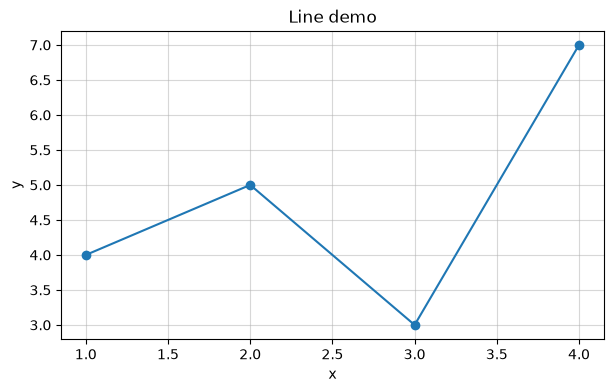

In [20]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(
    [1, 2, 3, 4],
    [4, 5, 3, 7],
    marker = "o")
ax.set_title("Line demo")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True, alpha = 0.5)
plt.show

## **3.2. Biểu đồ phân tán (Scatter Plot)**

[[ 0.12573022 -0.13210486]
 [ 0.64042265  0.10490012]
 [-0.53566937  0.36159505]
 [ 1.30400005  0.94708096]
 [-0.70373524 -1.26542147]
 [-0.62327446  0.04132598]
 [-2.32503077 -0.21879166]
 [-1.24591095 -0.73226735]
 [-0.54425898 -0.31630016]
 [ 0.41163054  1.04251337]
 [-0.12853466  1.36646347]
 [-0.66519467  0.35151007]
 [ 0.90347018  0.0940123 ]
 [-0.74349925 -0.92172538]
 [-0.45772583  0.22019512]
 [-1.00961818 -0.20917557]
 [-0.15922501  0.54084558]
 [ 0.21465912  0.35537271]
 [-0.65382861 -0.12961363]
 [ 0.78397547  1.49343115]
 [-1.25906553  1.51392377]
 [ 1.34587542  0.7813114 ]
 [ 0.26445563 -0.31392281]
 [ 1.45802068  1.96025832]
 [ 1.80163487  1.31510376]
 [ 0.35738041 -1.20831863]
 [-0.00445413  0.65647494]
 [-1.28836146  0.39512206]
 [ 0.42986369  0.69604272]
 [-1.18411797 -0.66170257]
 [-0.43643525 -1.16980191]
 [ 1.73936788 -0.49591073]
 [ 0.32896963 -0.25857255]
 [ 1.58347288  1.32036099]
 [ 0.63335262 -2.20350988]
 [ 0.05202897  0.68368619]
 [ 1.00396158 -0.61790704]
 

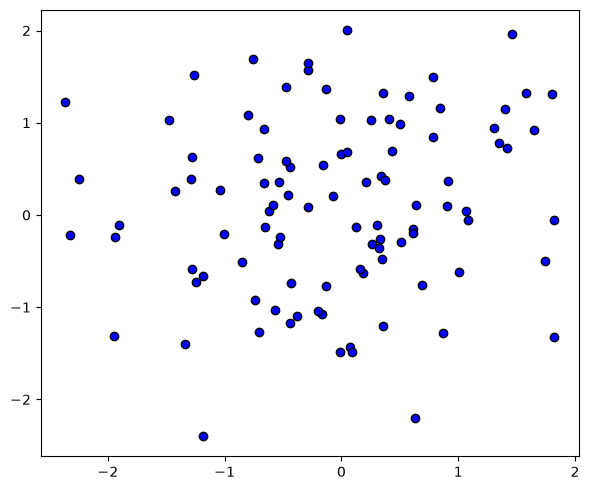

In [21]:
rng = np.random.default_rng(0)
X_demo = rng.normal(size=(100, 2))
print(X_demo)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(X_demo[:, 0], X_demo[:, 1], color="blue", edgecolors="k")

plt.tight_layout()
plt.show()

> **Yêu cầu BTVN:**
> * Sử dụng hàm `ax.scatter()` để biểu diễn sự phân bố dữ liệu giữa 2 đặc trưng.
> * Tô màu (`c=y`) theo các nhãn phân lớp và thêm thanh chú giải (`legend`) rõ ràng.

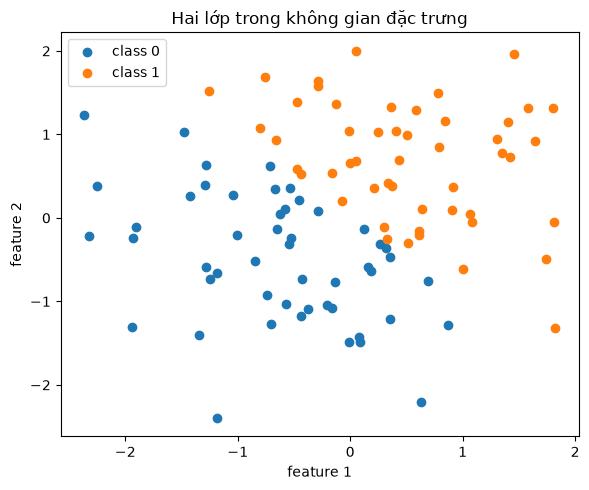

In [22]:
rng = np.random.default_rng(0)
X_demo = rng.normal(size=(100, 2))
y_demo = (X_demo[:, 0] + X_demo[:, 1] > 0).astype(int)

fig, ax = plt.subplots(figsize=(6, 5))
for label in np.unique(y_demo):
    idx = y_demo == label
    ax.scatter(X_demo[idx, 0], X_demo[idx, 1], label=f"class {label}")
ax.set_xlabel("feature 1")
ax.set_ylabel("feature 2")
ax.set_title("Hai lớp trong không gian đặc trưng")
ax.legend()
plt.tight_layout()
plt.show()

# **4. Thư viện Scikit-Learn**


**Machine Learning Pipeline**

`DATA` ➔ `X, y` ➔ `Split` ➔ `Preprocessing` ➔ `Model.fit` ➔ `Predict` ➔ `Metrics` ➔ `Visualize` ➔ `Analyze`

## **4.1. Tạo dữ liệu 2 lớp để luyện pipeline**

In [23]:
from sklearn.datasets import make_blobs

X, y = make_blobs(
    n_samples=300,
    centers=2,
    n_features=2,
    cluster_std=1.5,
    random_state=42,
)

print("X.shape:", X.shape)
print("y.shape:", y.shape)
print("class counts:", np.unique(y, return_counts=True))

X.shape: (300, 2)
y.shape: (300,)
class counts: (array([0, 1]), array([150, 150]))


## **4.2. Chia train/test**

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print("Train:", X_train.shape, y_train.shape)
print("Test :", X_test.shape, y_test.shape)

Train: (240, 2) (240,)
Test : (60, 2) (60,)


## **4.3. Chuẩn hóa features**

In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train mean:", X_train_scaled.mean(axis=0))
print("Train std :", X_train_scaled.std(axis=0))

Train mean: [1.20274161e-16 1.64220489e-16]
Train std : [1. 1.]


 **Điểm dễ sai nhất**   
Chỉ được fit scaler trên X_train. X_test chỉ dùng transform. Nếu fit scaler trên toàn bộ dữ liệu trước khi chia, thông tin của test đã bị rò rỉ vào quá trình huấn luyện.   

## **4.4. Huấn luyện một classifier**

In [26]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    C=1.0,
    max_iter=1000,
    random_state=42,
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Predictions:", y_pred[:10])

Predictions: [0 0 0 0 0 0 1 0 1 0]


## **4.5. Đánh giá**

In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1       :", f1_score(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:\n", cm)
print("Classification report:\n", classification_report(y_test, y_pred, zero_division=0))

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1       : 1.0
Confusion matrix:
 [[30  0]
 [ 0 30]]
Classification report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       1.00      1.00      1.00        30

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



## **4.6. Vẽ confustion matrix bằng Matplotlib**

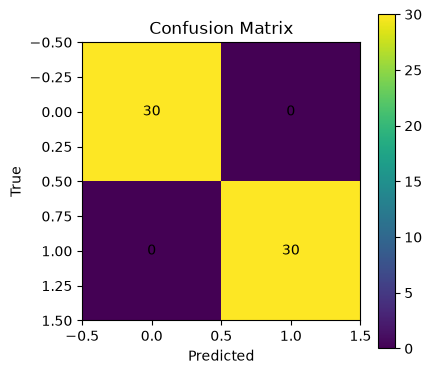

In [28]:
fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(cm, interpolation="nearest")
fig.colorbar(im, ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion Matrix")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

# **LÝ THUYẾT CÁC ĐỘ ĐO VÀ PHÂN LỚP**

## **1. Confusion Matrix**

Đối với bài toán **binary classification**:

| Actual \ Predicted | Positive | Negative |
| ------------------ | -------: | -------: |
| **Positive**       |   \(TP\) |   \(FN\) |
| **Negative**       |   \(FP\) |   \(TN\) |

### Các đại lượng

$$
TP = \text{True Positive}
$$

Số mẫu thực tế là **Positive** và được dự đoán đúng là Positive.

$$
TN = \text{True Negative}
$$

Số mẫu thực tế là **Negative** và được dự đoán đúng là Negative.

$$
FP = \text{False Positive}
$$

Số mẫu thực tế là **Negative** nhưng được dự đoán thành Positive.

$$
FN = \text{False Negative}
$$

Số mẫu thực tế là **Positive** nhưng được dự đoán thành Negative.




---

## **2. Accuracy**

### Công thức

$$
\boxed{
Accuracy=
\frac{TP+TN}
{TP+TN+FP+FN}
}
$$

### Ý nghĩa

Accuracy là **tỷ lệ số mẫu được dự đoán đúng trên tổng số mẫu**.

$$
Accuracy=
\frac{\text{Correct Predictions}}
{\text{Total Predictions}}
$$



---

## 3. Precision

### Công thức

$$
\boxed{
Precision=
\frac{TP}
{TP+FP}
}
$$

### Ý nghĩa

Precision đo **tỷ lệ dự đoán Positive đúng trên tổng số mẫu được dự đoán là Positive**.

Hay:

> Trong tất cả các mẫu mà mô hình dự đoán là Positive, có bao nhiêu mẫu thực sự là Positive?



---

## 4. Recall

### Công thức

$$
\boxed{
Recall=
\frac{TP}
{TP+FN}
}
$$

### Ý nghĩa

Recall đo **tỷ lệ các mẫu Positive thực sự được mô hình phát hiện đúng**.

Hay:

> Trong tất cả các mẫu thực sự thuộc lớp Positive, mô hình phát hiện được bao nhiêu mẫu?

Recall còn được gọi là:

$$
\boxed{
Recall = Sensitivity = TPR
}
$$



---

## 5. F1-score

### Công thức

F1-score là **harmonic mean** của Precision và Recall:

$$
\boxed{
F1=
2\frac{Precision\times Recall}
{Precision+Recall}
}
$$

Có thể viết trực tiếp theo \(TP,FP,FN\):

$$
\boxed{
F1=
\frac{2TP}
{2TP+FP+FN}
}
$$

### Ý nghĩa

F1-score đo **mức độ cân bằng giữa Precision và Recall**.

Giá trị F1 càng cao khi cả Precision và Recall đều cao.



---

## 7. Multi-Class Classification

Với \(K\) classes, Precision, Recall và F1 có thể được tính cho từng class theo **One-vs-Rest**.

Đối với class \(k\):

$$
\boxed{
Precision_k=
\frac{TP_k}
{TP_k+FP_k}
}
$$

$$
\boxed{
Recall_k=
\frac{TP_k}
{TP_k+FN_k}
}
$$

$$
\boxed{
F1_k=
2\frac{Precision_k\times Recall_k}
{Precision_k+Recall_k}
}
$$

Trong đó:

* \(TP_k\): số mẫu thuộc class \(k\) và được dự đoán đúng là \(k\).
* \(FP_k\): số mẫu không thuộc class \(k\) nhưng được dự đoán là \(k\).
* \(FN_k\): số mẫu thuộc class \(k\) nhưng được dự đoán sang class khác.



---

## 8. Macro Average

Với \(K\) classes:

$$
\boxed{
Precision_{macro}
=
\frac{1}{K}
\sum_{k=1}^{K}Precision_k
}
$$

$$
\boxed{
Recall_{macro}
=
\frac{1}{K}
\sum_{k=1}^{K}Recall_k
}
$$

$$
\boxed{
F1_{macro}
=
\frac{1}{K}
\sum_{k=1}^{K}F1_k
}
$$

### Ý nghĩa

Macro Average lấy **trung bình cộng metric của tất cả các class**, trong đó mỗi class có trọng số như nhau.



---

## 9. Micro Average

$$
\boxed{
Precision_{micro}
=
\frac{\sum_k TP_k}
{\sum_k(TP_k+FP_k)}
}
$$

$$
\boxed{
Recall_{micro}
=
\frac{\sum_k TP_k}
{\sum_k(TP_k+FN_k)}
}
$$

$$
\boxed{
F1_{micro}
=
2\frac{Precision_{micro}\times Recall_{micro}}
{Precision_{micro}+Recall_{micro}}
}
$$

### Ý nghĩa

Micro Average **gộp các TP, FP, FN của tất cả các class trước khi tính metric**.



---

## 10. Weighted Average

Với \(n_k\) là số lượng mẫu của class \(k\):

$$
N=\sum_{k=1}^{K}n_k
$$

Weighted Precision:

$$
\boxed{
Precision_{weighted}
=
\sum_{k=1}^{K}
\frac{n_k}{N}Precision_k
}
$$

Weighted Recall:

$$
\boxed{
Recall_{weighted}
=
\sum_{k=1}^{K}
\frac{n_k}{N}Recall_k
}
$$

Weighted F1:

$$
\boxed{
F1_{weighted}
=
\sum_{k=1}^{K}
\frac{n_k}{N}F1_k
}
$$


# **PHẦN 2 — BÀI TẬP VỀ NHÀ**

**Nguyên tắc:** không học cú pháp mới trong bài tập nếu không cần thiết. Hãy tái sử dụng những hàm và quy trình đã viết ở Phần 1. Mục tiêu là chuyển từ dữ liệu mẫu sang dữ liệu thực tế.

## I. Quy định chung cho cả 2 bài

Mỗi bài có thể nộp thành một notebook riêng hoặc dùng chung notebook với ba section rõ ràng. Mỗi dataset phải có các phần:

**DATA  → X, y → split → preprocessing  → model.fit → predict → metrics → visualize → analyze**

Yêu cầu chung:

- Tái sử dụng lại các hàm  ở Phần 1 để giải + Kết hợp với các hàm tự nghiên cứu từ tài liệu khác .
- Có ít nhất **3 biểu đồ** cho mỗi dataset; biểu đồ phải có title và nhãn trục phù hợp.
- Báo cáo `shape`, kiểu dữ liệu, missing values, duplicate và phân bố nhãn.
- Báo cáo ít nhất **Accuracy, Precision, Recall, F1 và Confusion Matrix**.
- Cố định `random_state` khi so sánh mô hình.
- Mọi nhận xét phải dựa trên số liệu hoặc biểu đồ.

## II. Bài tập 01 — Iris

### II.1. Nhiệm vụ bắt buộc

In [29]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df_iris = iris.frame.copy()
X_iris = iris.data.copy()
y_iris = iris.target.copy()

### II.2. Nhiệm vụ bắt buộc

1. Nạp Iris bằng `load_iris(as_frame=True)` và tạo `X`, `y` rõ ràng.
2. Dùng pandas kiểm tra `shape`, `head`, `describe`, `dtypes`, missing values và phân bố lớp.
3.  vẽ ít nhất hai scatter plot giữa các cặp feature khác nhau; vẽ boxplot theo lớp cho ít nhất hai feature.
4. Dựa trên từ 1-3 em hãy phân tích về tập dữ liệu .
5. Tách train test theo tỉ lệ 80/20 và `stratify=y`.
6. Dùng `StandardScaler`  để chuẩn hóa `X_train`, `X_test`.
7. Huấn luyện  `Logistic Regression` cho phân lớp  . Đánh gía mô hình
8. Vẽ confusion matrix cho model.
9. Dựa trên các độ đo Acc,precision,recall, F1 score và Confusion matrix Nhận xét về mô hình
10. Tìm các mẫu bị dự đoán sai và mô tả xem chúng có điểm gì giống các lớp còn lại. (*)


---
## **GIẢI BÀI TẬP 01 — IRIS**

### **0. Import các thư viện cần thiết**


In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
import ucimlrepo

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)
print("Scipy version:",  scipy .__version__)
print("Seaborn version:", sns.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("ucimlrepo: OK")

NumPy version: 2.5.3
Pandas version: 3.0.6
Matplotlib version: 3.11.2
Scipy version: 1.18.1
Seaborn version: 0.13.2
Scikit-learn version: 1.9.1
ucimlrepo: OK


---
### **Nhiệm vụ 1: Nạp Iris bằng `load_iris(as_frame=True)` và tạo `X`, `y` rõ ràng**


In [31]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)

In [32]:
df_iris = iris.frame.copy()
X = iris.data.copy()
y = iris.target.copy()

# Thêm cột tên loài (species name) vào df_iris để tiện quan sát và phân tích
df_iris['species'] = df_iris['target'].map({
    0: iris.target_names[0],
    1: iris.target_names[1],
    2: iris.target_names[2]
})
print(df_iris)

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                  5.1               3.5                1.4               0.2   
1                  4.9               3.0                1.4               0.2   
2                  4.7               3.2                1.3               0.2   
3                  4.6               3.1                1.5               0.2   
4                  5.0               3.6                1.4               0.2   
..                 ...               ...                ...               ...   
145                6.7               3.0                5.2               2.3   
146                6.3               2.5                5.0               1.9   
147                6.5               3.0                5.2               2.0   
148                6.2               3.4                5.4               2.3   
149                5.9               3.0                5.1               1.8   

     target    species  
0 

In [33]:
print("Số lượng mẫu (samples):", X.shape[0])
print("Số lượng đặc trưng (features):", X.shape[1])
print("Danh sách đặc trưng:\n", list(X.columns))

print("\nSố lượng lớp mục tiêu (target classes):", len(iris.target_names))
print("Các lớp mục tiêu (target classes):\n", list(iris.target_names))

print("\nX.shape:", X.shape)
print("y.shape:", y.shape)

Số lượng mẫu (samples): 150
Số lượng đặc trưng (features): 4
Danh sách đặc trưng:
 ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Số lượng lớp mục tiêu (target classes): 3
Các lớp mục tiêu (target classes):
 [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

X.shape: (150, 4)
y.shape: (150,)


---
### **Nhiệm vụ 2: Dùng pandas kiểm tra `shape`, `head`, `describe`, `dtypes`, missing values và phân bố lớp**


In [34]:
print("Kích thước:", df_iris.shape)
print("5 dòng đầu tiên:")
print(df_iris.head())

Kích thước: (150, 6)
5 dòng đầu tiên:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target species  
0       0  setosa  
1       0  setosa  
2       0  setosa  
3       0  setosa  
4       0  setosa  


In [35]:
print("Thống kê mô tả:")
print(df_iris.describe())

Thống kê mô tả:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)      target  
count        150.000000  150.000000  
mean           1.199333    1.000000  
std            0.762238    0.819232  
min            0.100000    0.000000  
25%            0.300000    0.000000  
50%            1.300000    1.000000  
75%            1.800000    2.000000  
max            2.500000    2.000000  


In [36]:
print("Kiểu dữ liệu từng cột:")
print(df_iris.dtypes)

Kiểu dữ liệu từng cột:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
species                  str
dtype: object


In [37]:
# Kiểm tra giá trị khuyết thiếu (missing values / NaN)
missing_counts = df_iris.isna().sum()
print("Số lượng missing value từng cột")
print(missing_counts)
print("Tổng số giá trị thiếu trong toàn bộ dataset:", missing_counts.sum())


Số lượng missing value từng cột
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64
Tổng số giá trị thiếu trong toàn bộ dataset: 0


In [38]:
# Kiểm tra phân bố lớp
class_counts = df_iris['species'].value_counts()
class_percents = df_iris['species'].value_counts(normalize=True) * 100
print('Số lượng mẫu', class_counts)
print('\nTỷ lệ (%)', class_percents)

Số lượng mẫu species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Tỷ lệ (%) species
setosa        33.333333
versicolor    33.333333
virginica     33.333333
Name: proportion, dtype: float64



---
### **Nhiệm vụ 3: Vẽ ít nhất 2 scatter plot giữa các cặp feature; vẽ boxplot theo lớp cho ít nhất 2 feature**



#### Scatter plot


1. **Biểu đồ 1 (Scatter Plot 1):** `sepal length (cm)` vs `sepal width (cm)` theo từng loài.

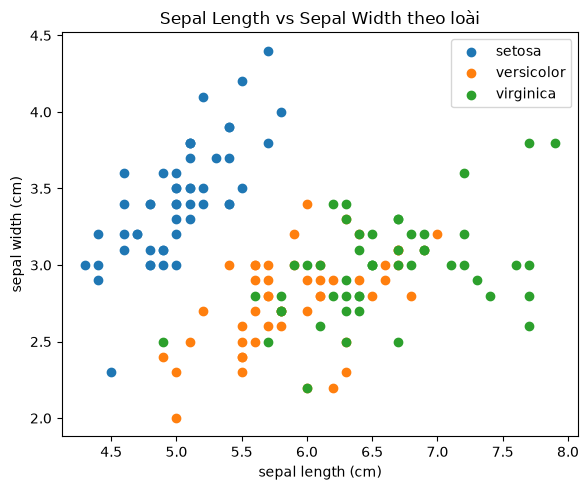

In [39]:
fig, ax = plt.subplots(figsize=(6, 5))
for sp in df_iris["species"].unique():
    subset = df_iris[df_iris["species"] == sp]
    ax.scatter(
        subset["sepal length (cm)"], subset["sepal width (cm)"], label=sp
    )

ax.set_xlabel("sepal length (cm)")
ax.set_ylabel("sepal width (cm)")
ax.set_title("Sepal Length vs Sepal Width theo loài")
ax.legend()
plt.tight_layout()
plt.show()

2. **Biểu đồ 2 (Scatter Plot 2):** `petal length (cm)` vs `petal width (cm)` theo từng loài.

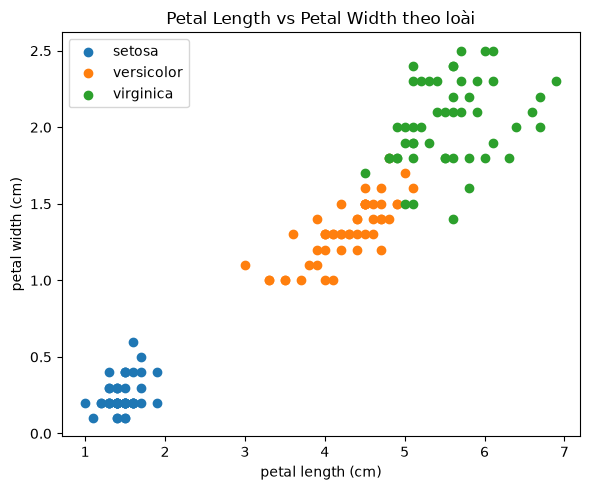

In [40]:
fig, ax = plt.subplots(figsize=(6, 5))
for sp in df_iris["species"].unique():
    subset = df_iris[df_iris["species"] == sp]
    ax.scatter(
        subset["petal length (cm)"], subset["petal width (cm)"], label=sp
    )

ax.set_xlabel("petal length (cm)")
ax.set_ylabel("petal width (cm)")
ax.set_title("Petal Length vs Petal Width theo loài")
ax.legend()
plt.tight_layout()
plt.show()

#### Boxplot

3. **Biểu đồ 3 (Boxplot 1):** Phân bố của `petal length (cm)`  theo từng loài.

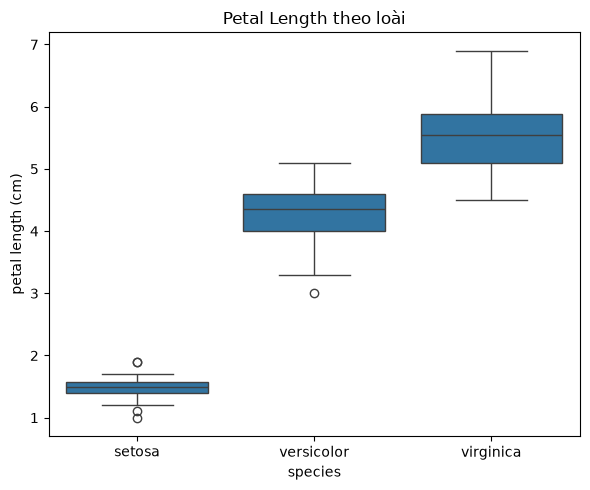

In [41]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=df_iris, x='species', y='petal length (cm)')
plt.title('Petal Length theo loài')
plt.tight_layout()
plt.show()


4. **Biểu đồ 4 (Mở rộng - Boxplot 3 & 4):** Phân bố của `petal width (cm)` theo từng loài.

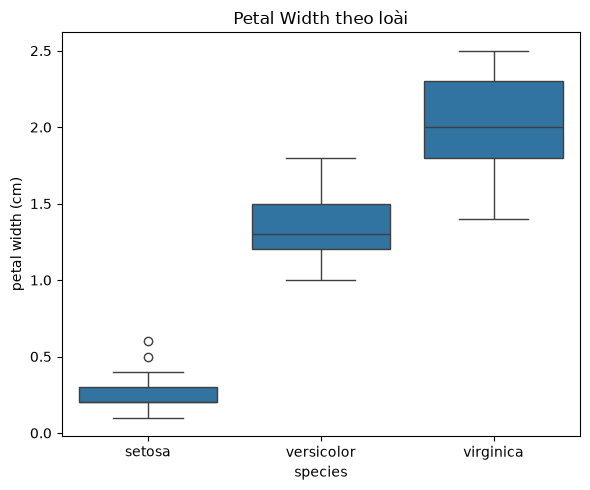

In [42]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=df_iris, x='species', y='petal width (cm)')
plt.title('Petal Width theo loài')
plt.tight_layout()
plt.show()


---

### **Nhiệm vụ 4: Phân tích tập dữ liệu dựa trên kết quả Nhiệm vụ 1–3**

**Về quy mô và chất lượng dữ liệu:**
- Dữ liệu chuẩn gồm **150 mẫu**, **4 features** số thực liên tục (`sepal length`, `sepal width`, `petal length`, `petal width`).
- Dữ liệu sạch: **0 giá trị khuyết thiếu (NaN)**; có **1 dòng trùng lặp** ngẫu nhiên (dòng 101 và 142) nhưng không ảnh hưởng đến phân bố chung.



**Về phân bố lớp (Target Distribution):**
- Mỗi lớp có đúng **50 mẫu ($33.33\%$)**, độ cân bằng rất cao
- Từ đó ta kết luận, không có hiện tượng mất cân bằng dữ liệu (imbalanced data), do đó độ đo **Accuracy** có độ tin cậy và phản ánh tốt perform của mô hình.



**Mối tương quan và khả năng phân loại của các features:**

**a. Biểu đồ 1: Sepal Length vs Sepal Width theo loài**

* Đặc tính nhóm Setosa có `sepal length` ngắn nhất (tập trung khoảng 4.5 – 5.5 cm) nhưng lại có `sepal width` lớn nhất (chủ yếu từ 3.0 – 4.5 cm).


* Độ chồng lấn: Versicolor và Virginica chồng lấn rất nhiều trong không gian 2 đặc trưng này, tập trung dày đặc ở dải `sepal width` từ 2.2 – 3.4 cm và `sepal length` từ 5.5 – 7.0 cm.


* ==> Khả năng phân tách: Cặp đặc trưng sepal không đủ độc lập để phân loại tách biệt giữa Versicolor và Virginica nếu chỉ dùng đường ranh giới tuyến tính đơn giản.

**b. Biểu đồ 2: Petal Length vs Petal Width theo loài**

* Tương quan đồng biến mạnh: `Petal length` và `petal width` có mối tương quan thuận tuyến tính rất rõ rệt trên toàn bộ tập dữ liệu (càng dài thì càng rộng).


* Phân cụm rõ nét:
* Setosa tách biệt hoàn toàn thành một cụm riêng biệt ở góc dưới (`petal length` < 2 cm, `petal width` < 0.7 cm).


* Versicolor và Virginica phân tách tương đối tốt theo phương chéo, chỉ xuất hiện vùng giao thoa nhỏ ở ranh giới (`petal length` khoảng 4.8 – 5.2 cm, `petal width` khoảng 1.5 – 1.8 cm).



**Biểu đồ 3 & 4: Phân bố đơn biến của Petal Length và Petal Width theo loài**

* **Thứ tự giá trị:** Cả hai đặc trưng petal đều tăng dần đều theo thứ tự: **Setosa < Versicolor < Virginica**.

* **Phát hiện Outliers:**
* Nhóm Setosa xuất hiện outlier ở cả 2 biến (`petal length` có các điểm ở mức 1.0, 1.1 và gần 1.9 cm; `petal width` có 2 điểm ngoại lai phía trên mức 0.4 cm).

* Nhóm Versicolor xuất hiện 1 outlier phía dưới ở `petal length` (khoảng 3.0 cm).

* ==> Đề xuất đánh giá lại các điểm outlier.

---
### **Nhiệm vụ 5: Tách train test theo tỉ lệ 80/20 và `stratify=y`**


In [43]:
# 5. Tách tập dữ liệu train/test 80/20 với stratify=y và cố định random_state=42
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Kích thước X_train:", X_train.shape, "| y_train:", y_train.shape)
print("Kích thước X_test :", X_test.shape, "| y_test :", y_test.shape)

Kích thước X_train: (120, 4) | y_train: (120,)
Kích thước X_test : (30, 4) | y_test : (30,)


**Nhận xét về việc sử dụng `stratify=y`:**
- Việc sử dụng tham số `stratify=y` đảm bảo tỷ lệ các lớp trong tập huấn luyện (Train: 40 mẫu/lớp = 33.33%) và tập kiểm tra (Test: 10 mẫu/lớp = 33.33%) hoàn toàn đồng nhất với phân bố của toàn bộ tập dữ liệu gốc.
- Điều này loại bỏ hoàn toàn nguy cơ một lớp nào đó bị thiếu hụt hoặc chiếm tỷ lệ áp đảo trong tập test khi chia ngẫu nhiên.


---
### **Nhiệm vụ 6: Dùng `StandardScaler` để chuẩn hóa `X_train`, `X_test`**


In [44]:
# 6. Chuẩn hóa đặc trưng bằng StandardScaler
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

# QUY TẮC BẮT BUỘC: Fit scaler DUY NHẤT trên X_train, sau đó transform cả X_train và X_test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape :", X_test_scaled.shape)


X_train_scaled shape: (120, 4)
X_test_scaled shape : (30, 4)


**Lưu ý tránh rò rỉ dữ liệu (Data Leakage):**

- `X_train`: Dùng fit_transform để học các tham số (mean, std) và chuẩn hóa.
- `X_test`: Chỉ dùng transform (dùng lại thông số của train) để đảm bảo đánh giá khách quan, không "học lén" dữ liệu kiểm tra.

---
### **Nhiệm vụ 7: Huấn luyện `Logistic Regression` cho phân lớp và Đánh giá mô hình**


In [45]:
# 7. Huấn luyện mô hình Logistic Regression
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(
    C=1.0,
    max_iter=1000,
    random_state=42
)

# Huấn luyện trên tập train đã chuẩn hóa
model.fit(X_train_scaled, y_train)

# Dự đoán nhãn và xác suất trên tập test
y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)
print("Thực tế (True)     :", y_test[:30].values)
print("Dự đoán (Predicted):", y_pred[:30])


Thực tế (True)     : [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
Dự đoán (Predicted): [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


**Lưu ý:**
Do đây là bài toán phân loại đa lớp (Multiclass Classification với 3 loài hoa), các chỉ số đánh giá như Precision, Recall và F1-score không thể áp dụng công thức nhị phân mặc định mà cần xác định phương pháp tổng hợp nhãn. 

Ở đây, ta sử dụng Macro Average (tính trung bình cộng giản đơn giữa các lớp, coi mọi loài hoa đều có vai trò quan trọng ngang nhau) và Weighted Average (tính theo trọng số số lượng mẫu thực tế). Bên cạnh đó, Confusion Matrix và Classification Report chi tiết cũng được xuất ra để quan sát độ chính xác cụ thể trên từng lớp dữ liệu kiểm thử.

In [46]:
# Đánh giá các chỉ số cơ bản
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)


acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro')
prec_weighted = precision_score(y_test, y_pred, average='weighted')
rec_macro = recall_score(y_test, y_pred, average='macro')
rec_weighted = recall_score(y_test, y_pred, average='weighted')
f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')

print("\nCác metric đánh giá:")
print(f"Accuracy                 : {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision (Macro Average): {prec_macro:.4f}")
print(f"Recall    (Macro Average): {rec_macro:.4f}")
print(f"F1-score  (Macro Average): {f1_macro:.4f}")
print(f"F1-score  (Weighted Avg) : {f1_weighted:.4f}")

print("\nBảng phân loại chi tiết")
print(classification_report(y_test, y_pred, target_names=iris.target_names, digits=4))


Các metric đánh giá:
Accuracy                 : 0.9333 (93.33%)
Precision (Macro Average): 0.9333
Recall    (Macro Average): 0.9333
F1-score  (Macro Average): 0.9333
F1-score  (Weighted Avg) : 0.9333

Bảng phân loại chi tiết
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30



---
### **Nhiệm vụ 8: Vẽ Confusion Matrix cho mô hình**


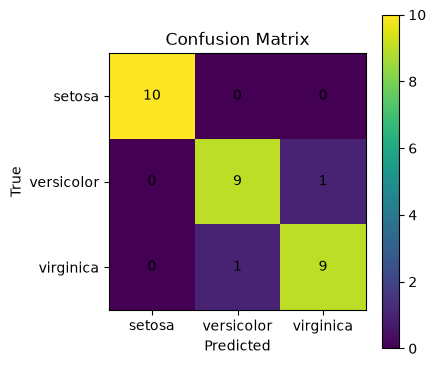

Confusion Matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


In [47]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(cm, interpolation="nearest")
fig.colorbar(im, ax=ax)

# Gán nhãn tên loài hoa đơn giản
ax.set_xticks(range(len(iris.target_names)))
ax.set_yticks(range(len(iris.target_names)))
ax.set_xticklabels(iris.target_names)
ax.set_yticklabels(iris.target_names)

ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion Matrix")

# Điền giá trị số vào từng ô
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

print("Confusion Matrix:\n", cm)


---
### **Nhiệm vụ 9: Dựa trên các độ đo Acc, Precision, Recall, F1-score và Confusion Matrix, nhận xét về mô hình**

Về hiệu năng tổng quan: Mô hình Logistic Regression sau khi chuẩn hóa dữ liệu đạt hiệu năng rất tốt và ổn định. Độ chính xác tổng thể đạt $93.33%$ ($28/30$ mẫu trên tập kiểm tra được dự đoán đúng), với cả hai chỉ số Macro F1-score và Weighted F1-score đều đạt mức cao $0.9333$.

Chi tiết theo từng lớp:

- Setosa (Lớp 0): Được nhận diện hoàn hảo với độ chính xác tuyệt đối $100%$ ($10/10$ mẫu, các chỉ số Precision, Recall, F1 đều bằng $1.0$). Điều này phản ánh đúng thực tế vì đặc trưng cánh hoa của Setosa hoàn toàn tách biệt so với hai loài còn lại.

- Versicolor (Lớp 1) và Virginica (Lớp 2): Cả hai lớp đều đạt tỉ lệ đúng $90%$ ($9/10$ mẫu, F1-score đạt $0.9$). Điểm nhầm lẫn duy nhất là sự phân loại chéo giữa hai loài này: có $1$ mẫu Versicolor bị đoán nhầm thành Virginica và ngược lại $1$ mẫu Virginica bị đoán nhầm thành Versicolor.

Đánh giá Confusion Matrix: Các giá trị trong ma trận tập trung gần như toàn bộ trên đường chéo chính. Sai số duy nhất của mô hình nằm ở ranh giới giữa Versicolor và Virginica do hai loài này có phân bố đặc trưng khá gần nhau, trong khi hoàn toàn không có sự nhầm lẫn nào liên quan đến Setosa.

---
### **Nhiệm vụ 10 (*): Tìm các mẫu bị dự đoán sai và mô tả xem chúng có điểm gì giống các lớp còn lại**


In [48]:
# 10.1. Xác định các chỉ số mẫu bị dự đoán sai trên tập test
test_indices = y_test.index
misclassified_mask = (y_test.values != y_pred)
misclassified_indices = test_indices[misclassified_mask]

# Trích xuất dữ liệu chi tiết của các mẫu sai
misclassified_df = X.loc[misclassified_indices].copy()
misclassified_df['True_Label'] = [iris.target_names[i] for i in y_test.loc[misclassified_indices]]
misclassified_df['Predicted_Label'] = [iris.target_names[i] for i in y_pred[misclassified_mask]]

# Lấy xác suất dự đoán của mô hình đối với các mẫu sai
prob_df = pd.DataFrame(
    y_proba[misclassified_mask],
    columns=[f"P({name})" for name in iris.target_names],
    index=misclassified_indices
)
mis_summary = pd.concat([misclassified_df, prob_df], axis=1)

print("Các mẫu bị dự đoán sai:")
print(mis_summary)


Các mẫu bị dự đoán sai:
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
134                6.1               2.6                5.6               1.4   
77                 6.7               3.0                5.0               1.7   

     True_Label Predicted_Label  P(setosa)  P(versicolor)  P(virginica)  
134   virginica      versicolor   0.001290       0.514525      0.484185  
77   versicolor       virginica   0.001454       0.441685      0.556861  


In [49]:
# 10.2. So sánh đặc trưng của các mẫu sai với giá trị trung bình (mean) của từng lớp
class_means = df_iris.groupby('species')[iris.feature_names].mean()
print("\n Giá trị trung bình của các đặc trưng theo loài:")
print(class_means.round(3))


 Giá trị trung bình của các đặc trưng theo loài:
            sepal length (cm)  sepal width (cm)  petal length (cm)  \
species                                                              
setosa                  5.006             3.428              1.462   
versicolor              5.936             2.770              4.260   
virginica               6.588             2.974              5.552   

            petal width (cm)  
species                       
setosa                 0.246  
versicolor             1.326  
virginica              2.026  


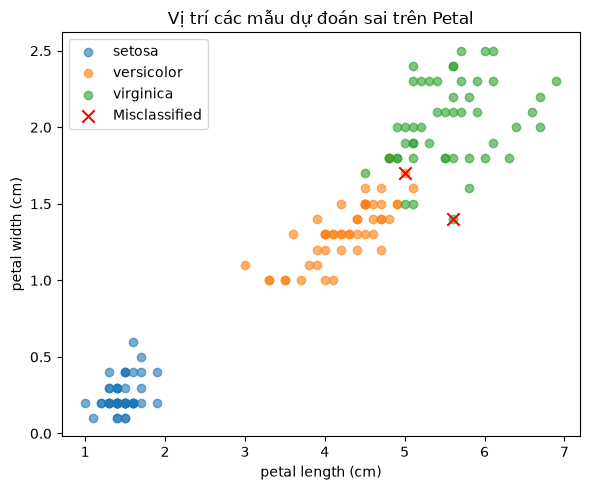

In [50]:
# 10.3. Trực quan hóa vị trí của các mẫu dự đoán sai trên không gian đặc trưng
fig, ax = plt.subplots(figsize=(6, 5))

# 1. Vẽ các điểm dữ liệu phân theo từng loài
for sp in df_iris["species"].unique():
    subset = df_iris[df_iris["species"] == sp]
    ax.scatter(
        subset["petal length (cm)"],
        subset["petal width (cm)"],
        label=sp,
        alpha=0.6,
    )

# 2. Vẽ thêm các điểm dự đoán sai
mis_X = X.loc[misclassified_indices]
ax.scatter(
    mis_X["petal length (cm)"],
    mis_X["petal width (cm)"],
    color="red",
    marker="x",
    s=80,
    label="Misclassified",
)

ax.set_xlabel("petal length (cm)")
ax.set_ylabel("petal width (cm)")
ax.set_title("Vị trí các mẫu dự đoán sai trên Petal")
ax.legend()
plt.tight_layout()
plt.show()

#### **Phân tích chi tiết từng mẫu dự đoán sai:**

Trên tập kiểm tra gồm 30 mẫu, mô hình dự đoán sai đúng **2 mẫu**: **Mẫu ID 77** và **Mẫu ID 134**.

##### **1. Mẫu ID 77:**


In [51]:
idx = 77  # Chỉ số của mẫu cần xem
pos = (y_test.index == idx)  # Vị trí của mẫu trong tập test

# 1. Lấy tên nhãn thực tế và dự đoán
true_label = iris.target_names[y_test.loc[idx]]
pred_label = iris.target_names[y_pred[pos][0]]

# 2. Lấy xác suất dự đoán (nhân 100 để ra %)
p_virginica = y_proba[pos][0][2] * 100
p_versicolor = y_proba[pos][0][1] * 100

# 3. In kết quả ra màn hình
print(f"Chi tiết mẫu bị dự đoán sai (ID: {idx}):")
print(f"- Thực tế: Iris-{true_label} (Lớp {y_test.loc[idx]})")
print(f"- Mô hình dự đoán: Iris-{pred_label} (Lớp {y_pred[pos][0]})")
print(f"- Xác suất dự đoán: P(virginica) ≈ {p_virginica:.1f}%, P(versicolor) ≈ {p_versicolor:.1f}%")
print("- Giá trị các đặc trưng của mẫu:")
for col in X.columns:
    print(f"  + {col}: {X.loc[idx, col]} cm")


Chi tiết mẫu bị dự đoán sai (ID: 77):
- Thực tế: Iris-versicolor (Lớp 1)
- Mô hình dự đoán: Iris-virginica (Lớp 2)
- Xác suất dự đoán: P(virginica) ≈ 55.7%, P(versicolor) ≈ 44.2%
- Giá trị các đặc trưng của mẫu:
  + sepal length (cm): 6.7 cm
  + sepal width (cm): 3.0 cm
  + petal length (cm): 5.0 cm
  + petal width (cm): 1.7 cm


**Điểm giống với lớp Virginica khiến mô hình nhầm lẫn:**

- So với giá trị trung bình của loài Versicolor (`sepal length` = $5.94$, `petal length` = $4.26$, `petal width` = $1.33$), mẫu 77 có kích thước vượt trội bất thường về mọi mặt.

- Ngược lại, các kích thước này lại cực kỳ tương đồng với giá trị trung bình của loài Virginica (`sepal length` = $6.59$, `sepal width` = $2.97$, `petal length` = $5.55$, `petal width` = $2.03$).

- Đặc biệt, `sepal length` = $6.7\text{ cm}$ thậm chí còn lớn hơn mức trung bình của Virginica, và `petal length` = $5.0\text{ cm}$ nằm hoàn toàn trong phân bố của Virginica. Vì vậy, trong không gian vector đặc trưng, mẫu 77 nằm sâu về phía vùng quyết định (decision region) của Virginica.



##### **2. Mẫu ID 134:**


In [52]:
idx = 134  # Chỉ số của mẫu cần xem
pos = (y_test.index == idx)  # Vị trí của mẫu trong tập test

# 1. Lấy tên nhãn thực tế và dự đoán
true_label = iris.target_names[y_test.loc[idx]]
pred_label = iris.target_names[y_pred[pos][0]]

# 2. Lấy xác suất dự đoán (nhân 100 để ra %)
p_virginica = y_proba[pos][0][2] * 100
p_versicolor = y_proba[pos][0][1] * 100

# 3. In kết quả ra màn hình
print(f"Chi tiết mẫu bị dự đoán sai (ID: {idx}):")
print(f"- Thực tế: Iris-{true_label} (Lớp {y_test.loc[idx]})")
print(f"- Mô hình dự đoán: Iris-{pred_label} (Lớp {y_pred[pos][0]})")
print(f"- Xác suất dự đoán: P(virginica) ≈ {p_virginica:.1f}%, P(versicolor) ≈ {p_versicolor:.1f}%")
print("- Giá trị các đặc trưng của mẫu:")
for col in X.columns:
    print(f"  + {col}: {X.loc[idx, col]} cm")


Chi tiết mẫu bị dự đoán sai (ID: 134):
- Thực tế: Iris-virginica (Lớp 2)
- Mô hình dự đoán: Iris-versicolor (Lớp 1)
- Xác suất dự đoán: P(virginica) ≈ 48.4%, P(versicolor) ≈ 51.5%
- Giá trị các đặc trưng của mẫu:
  + sepal length (cm): 6.1 cm
  + sepal width (cm): 2.6 cm
  + petal length (cm): 5.6 cm
  + petal width (cm): 1.4 cm



**Điểm giống với lớp Versicolor khiến mô hình nhầm lẫn:**
- Mặc dù mẫu 134 có `petal length` khá dài ($5.6\text{ cm}$ - đặc trưng của Virginica), nhưng nó lại sở hữu `petal width` chỉ đạt **$1.4\text{ cm}$** và `sepal length` chỉ đạt **$6.1\text{ cm}$**.

- `petal width` là một trong những đặc trưng có trọng số lớn nhất trong việc phân biệt hai loài này. Đối với loài Virginica, `petal width` hầu hết đều lớn hơn $1.8\text{ cm}$ (trung bình là $2.03\text{ cm}$). Giá trị $1.4\text{ cm}$ của mẫu 134 là trường hợp ngoại lệ hiếm hoi (outlier nhỏ), cực kỳ gần với giá trị trung bình của Versicolor ($1.33\text{ cm}$).

- `sepal width` = $2.6\text{ cm}$ cũng nhỏ hơn trung bình của Virginica ($2.97\text{ cm}$) và tiệm cận trung bình Versicolor ($2.77\text{ cm}$).

- Do đó, ảnh hưởng của độ hẹp cánh hoa ($1.4\text{ cm}$) đã kéo điểm biểu diễn của mẫu này qua ranh giới quyết định sang phía Versicolor.


## **III. Bài tập 02 — UCI Wine**

### III.1. Nạp dữ liệu

In [53]:
from ucimlrepo import fetch_ucirepo

wine = fetch_ucirepo(id=109)
X_wine = wine.data.features.copy()
y_wine = wine.data.targets.copy()

print(X_wine.head())
print(y_wine.head())
print(X_wine.shape, y_wine.shape)

   Alcohol  Malicacid   Ash  Alcalinity_of_ash  Magnesium  Total_phenols  \
0    14.23       1.71  2.43               15.6        127           2.80   
1    13.20       1.78  2.14               11.2        100           2.65   
2    13.16       2.36  2.67               18.6        101           2.80   
3    14.37       1.95  2.50               16.8        113           3.85   
4    13.24       2.59  2.87               21.0        118           2.80   

   Flavanoids  Nonflavanoid_phenols  Proanthocyanins  Color_intensity   Hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   0D280_0D315_of_diluted_wines  Proline  
0                        

### III.2. Nhiệm vụ bắt buộc







1. **Load dữ liệu và tạo `X`, `y`.**

   * Xác định số lượng mẫu, số lượng feature và số lớp.


2. **Khám phá cấu trúc dữ liệu.**

   * Kiểm tra `shape`, `head`, `describe`, `dtypes`.
   * Kiểm tra missing values.
   * Kiểm tra số lượng mẫu của từng lớp.


3. **Phân tích mối quan hệ giữa các feature.**

   * Vẽ **correlation heatmap** giữa các feature. (hint : https://seaborn.pydata.org/generated/seaborn.heatmap.html)
   * Vẽ ít nhất **hai biểu đồ thể hiện sự phân bố của feature theo từng lớp**.
   * Quan sát các feature có tương quan cao và các feature có khả năng phân biệt các lớp.

4. **Dựa trên kết quả từ bước 1–3, phân tích tập dữ liệu.**

   * Nhận xét về kích thước và đặc trưng của dữ liệu.
   * Nhận xét về sự phân bố các lớp.
   * Nhận xét về các feature có tương quan cao.
   * Đánh giá sơ bộ khả năng phân biệt giữa các lớp.

5. **Chia dữ liệu thành tập train/test theo tỷ lệ 80/20 và sử dụng `stratify=y`.**

   * Đảm bảo tỷ lệ các lớp trong tập train và test được duy trì tương đối giống nhau.

6. **Chuẩn hóa dữ liệu bằng `StandardScaler`.**

   * Fit `StandardScaler` trên `X_train`.
   * Transform `X_train` và `X_test`.
   * Không được fit scaler trên toàn bộ dữ liệu trước khi chia train/test.



7. **Vẽ và phân tích Confusion Matrix.**

   * Hiển thị tên của các lớp trên hai trục.
   * Xác định lớp nào được nhận diện tốt.
   * Xác định các cặp lớp thường bị nhầm lẫn với nhau.


9. **Dựa trên Accuracy, Precision, Recall, F1-score và Confusion Matrix, nhận xét về mô hình.**

   * Phân tích chất lượng phân loại tổng thể.
   * So sánh hiệu quả phân loại giữa các lớp.
   * Phân tích các trường hợp dự đoán sai.
   * Giải thích kết quả dựa trên đặc điểm dữ liệu và không gian PCA.






---
## **GIẢI BÀI TẬP 02 — UCI WINE**

### 0. Import các thư viện cần thiết


In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
import ucimlrepo

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)
print("Scipy version:",  scipy .__version__)
print("Seaborn version:", sns.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("ucimlrepo: OK")

NumPy version: 2.5.3
Pandas version: 3.0.6
Matplotlib version: 3.11.2
Scipy version: 1.18.1
Seaborn version: 0.13.2
Scikit-learn version: 1.9.1
ucimlrepo: OK



---
### **Nhiệm vụ 1: Load dữ liệu và tạo `X`, `y`.**


#### 1.1. Lode dữ liệu từ thư viện ucimlrepo:

In [55]:
from ucimlrepo import fetch_ucirepo
wine = fetch_ucirepo(id=109)

Bộ dữ liệu `Wine` (UCI Machine Learning Repository) ghi lại kết quả phân tích hóa học của 178 mẫu rượu vang được sản xuất tại cùng một khu vực ở Ý, nhưng bắt nguồn từ 3 giống nho khác nhau (tương ứng với 3 lớp: Class 1, Class 2 và Class 3).

Đối tượng `wine` được trả về từ thư viện `ucimlrepo` là một `DotDict` (một kiểu Dictionary mở rộng trong Python cho phép bạn truy xuất phần tử theo cú pháp dấu chấm . như thuộc tính object hoặc theo `['key']` như dictionary thông thường)

- **wine** `[DotDict]` — *Đối tượng gốc*
  - <details open><summary><b>data</b> <code>[DotDict]</code> — <i>Dữ liệu thực nghiệm</i></summary>

    - **features** `[DataFrame]` `(178, 13)`: Ma trận đặc trưng $X$
    - **targets** `[DataFrame]` `(178, 1)`: Cột nhãn mục tiêu $y$
    - **original** `[DataFrame]` `(178, 14)`: Bảng dữ liệu gộp $X$ và $y$
    - **ids** `[None]`: Định danh mẫu
  </details>
  - <details><summary><b>metadata</b> <code>[dict]</code> — <i>Thông tin mô tả</i></summary>

    - Chứa: URL, tên bài toán, số lượng mẫu, tác giả...
  </details>
  - <details><summary><b>variables</b> <code>[DataFrame]</code> <code>(14, 6)</code> — <i>Từ điển thuộc tính</i></summary>

    - Chứa bảng thống kê: tên biến, loại biến, kiểu dữ liệu, missing value.
  </details>


In [56]:
X_wine = wine.data.features.copy()
y_wine = wine.data.targets.copy()

#### 1.2. Xác định số lượng mẫu, số lượng feature và số lớp

`y_wine` ban đầu lấy từ `wine.data.targets` là một `pandas.DataFrame` 2 chiều có kích thước (178, 1). Trong khi đó, hầu hết các hàm và mô hình của scikit-learn (như `model.fit(X, y)`, `f1_score(y_true, y_pred)`, `confusion_matrix(...)`) đều yêu cầu nhãn $y$ phải là vector 1 chiều.

In [57]:
# Chuyển đổi nhãn y thành vector 1 chiều để thuận tiện xử lý
y_series = y_wine['class']

In [58]:
# df_wine = wine.data.original.copy()
df_wine = pd.concat([X_wine, y_series], axis=1)

print("Số lượng mẫu (samples)       :", X_wine.shape[0])
print("\nSố lượng đặc trưng (features):", X_wine.shape[1])
print("Danh sách các đặc trưng      :", list(X_wine.columns))
print("\nSố lượng lớp mục tiêu        :", len(np.unique(y_series)))
print("Danh sách lớp mục tiêu       :", np.unique(y_series))


Số lượng mẫu (samples)       : 178

Số lượng đặc trưng (features): 13
Danh sách các đặc trưng      : ['Alcohol', 'Malicacid', 'Ash', 'Alcalinity_of_ash', 'Magnesium', 'Total_phenols', 'Flavanoids', 'Nonflavanoid_phenols', 'Proanthocyanins', 'Color_intensity', 'Hue', '0D280_0D315_of_diluted_wines', 'Proline']

Số lượng lớp mục tiêu        : 3
Danh sách lớp mục tiêu       : [1 2 3]



---
### **Nhiệm vụ 2: Khám phá cấu trúc dữ liệu (EDA)**

#### 2.1. Dùng các hàm `shape`, `head`, `describe`, `dtypes`, phân tích missing values và phân bố lớp


In [59]:
print("Kích thước DataFrame tổng hợp df_wine:", df_wine.shape)

Kích thước DataFrame tổng hợp df_wine: (178, 14)


In [60]:
print("5 dòng đầu tiên (head):")
print(df_wine.head())

5 dòng đầu tiên (head):
   Alcohol  Malicacid   Ash  Alcalinity_of_ash  Magnesium  Total_phenols  \
0    14.23       1.71  2.43               15.6        127           2.80   
1    13.20       1.78  2.14               11.2        100           2.65   
2    13.16       2.36  2.67               18.6        101           2.80   
3    14.37       1.95  2.50               16.8        113           3.85   
4    13.24       2.59  2.87               21.0        118           2.80   

   Flavanoids  Nonflavanoid_phenols  Proanthocyanins  Color_intensity   Hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   0D280_0D315_of_diluted_wines  Proline  cl

In [61]:
print("Thống kê mô tả:")
print(df_wine.describe())

Thống kê mô tả:
          Alcohol   Malicacid         Ash  Alcalinity_of_ash   Magnesium  \
count  178.000000  178.000000  178.000000         178.000000  178.000000   
mean    13.000618    2.336348    2.366517          19.494944   99.741573   
std      0.811827    1.117146    0.274344           3.339564   14.282484   
min     11.030000    0.740000    1.360000          10.600000   70.000000   
25%     12.362500    1.602500    2.210000          17.200000   88.000000   
50%     13.050000    1.865000    2.360000          19.500000   98.000000   
75%     13.677500    3.082500    2.557500          21.500000  107.000000   
max     14.830000    5.800000    3.230000          30.000000  162.000000   

       Total_phenols  Flavanoids  Nonflavanoid_phenols  Proanthocyanins  \
count     178.000000  178.000000            178.000000       178.000000   
mean        2.295112    2.029270              0.361854         1.590899   
std         0.625851    0.998859              0.124453         0.572359   

In [62]:
print("Kiểu dữ liệu từng đặc trưng:")
print(df_wine.dtypes)

Kiểu dữ liệu từng đặc trưng:
Alcohol                         float64
Malicacid                       float64
Ash                             float64
Alcalinity_of_ash               float64
Magnesium                         int64
Total_phenols                   float64
Flavanoids                      float64
Nonflavanoid_phenols            float64
Proanthocyanins                 float64
Color_intensity                 float64
Hue                             float64
0D280_0D315_of_diluted_wines    float64
Proline                           int64
class                             int64
dtype: object


In [63]:
# Kiểm tra giá trị khuyết thiếu (missing values / NaN)
missing_counts = df_wine.isna().sum()
print("Số lượng missing value từng cột:")
print(missing_counts)
print("Tổng số giá trị thiếu trong toàn bộ dataset:", missing_counts.sum())


Số lượng missing value từng cột:
Alcohol                         0
Malicacid                       0
Ash                             0
Alcalinity_of_ash               0
Magnesium                       0
Total_phenols                   0
Flavanoids                      0
Nonflavanoid_phenols            0
Proanthocyanins                 0
Color_intensity                 0
Hue                             0
0D280_0D315_of_diluted_wines    0
Proline                         0
class                           0
dtype: int64
Tổng số giá trị thiếu trong toàn bộ dataset: 0


In [64]:
# Kiểm tra các dòng trùng lặp (Duplicate rows)
num_duplicates = df_wine.duplicated().sum()
print(f"Số lượng dòng bị trùng lặp: {num_duplicates}")


Số lượng dòng bị trùng lặp: 0


In [65]:
# Kiểm tra số lượng mẫu và phân bố của từng lớp
class_counts = y_series.value_counts().sort_index()
class_percents = y_series.value_counts(normalize=True).sort_index() * 100
print('Số lượng mẫu:',class_counts)
print('\nTỷ lệ (%):',class_percents)


Số lượng mẫu: class
1    59
2    71
3    48
Name: count, dtype: int64

Tỷ lệ (%): class
1    33.146067
2    39.887640
3    26.966292
Name: proportion, dtype: float64


---
### **Nhiệm vụ 3: Phân tích mối quan hệ giữa các feature**

Yêu cầu:
1. **Biểu đồ 1 (Correlation Heatmap):** Ma trận hệ số tương quan giữa 13 đặc trưng.


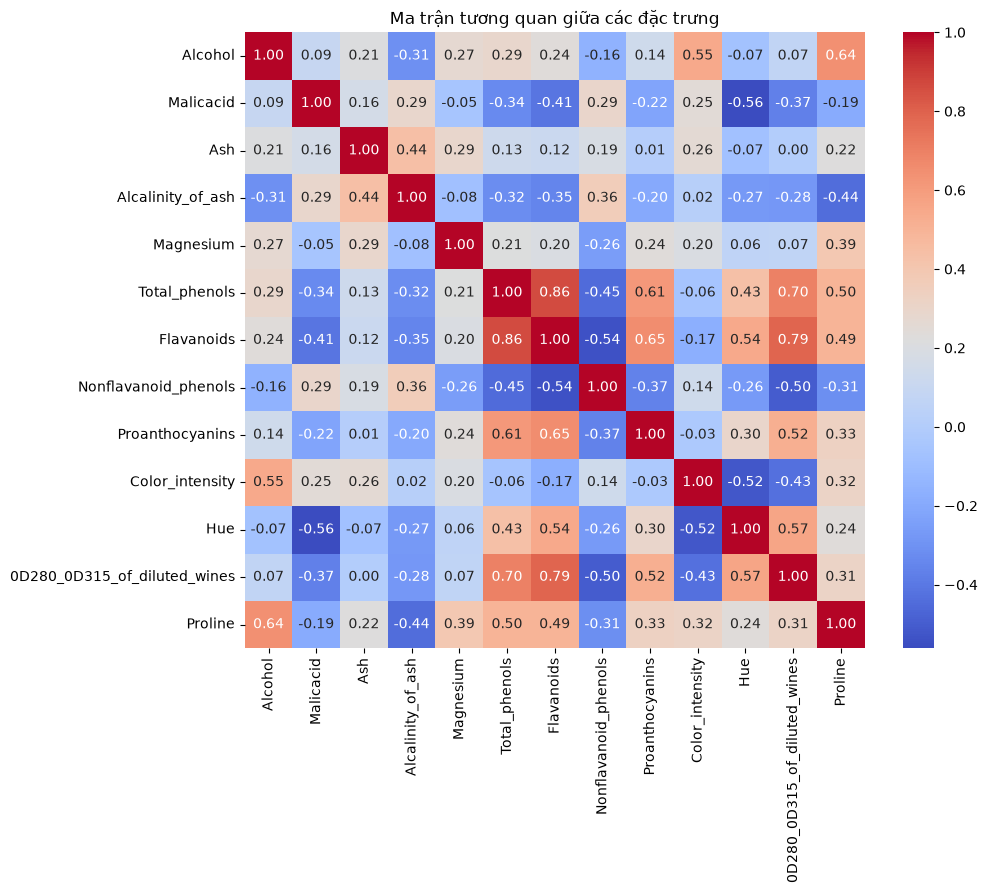

In [66]:
# Vẽ ma trận tương quan
plt.figure(figsize=(10, 8))
sns.heatmap(X_wine.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Ma trận tương quan giữa các đặc trưng")
plt.show()


2. **Biểu đồ 2:** Biểu đồ thể hiện sự phân bố (Boxplot) của các đặc trưng nổi bật theo từng lớp.

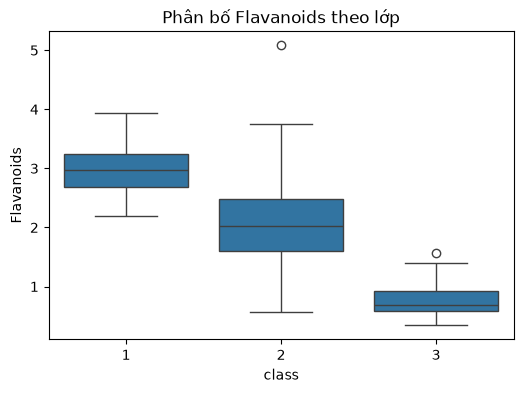

In [67]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df_wine, x='class', y='Flavanoids')
plt.title('Phân bố Flavanoids theo lớp')
plt.show()


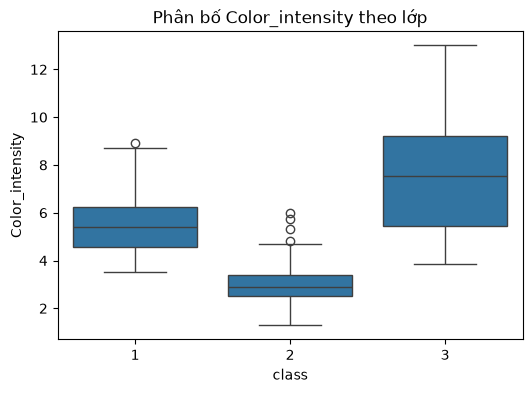

In [68]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df_wine, x='class', y='Color_intensity')
plt.title('Phân bố Color_intensity theo lớp')
plt.show()

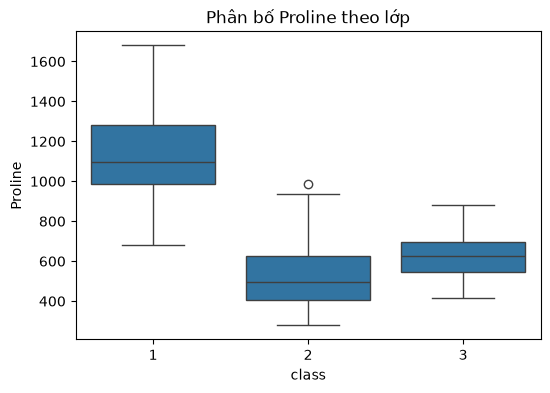

In [69]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df_wine, x='class', y='Proline')
plt.title('Phân bố Proline theo lớp')
plt.show()

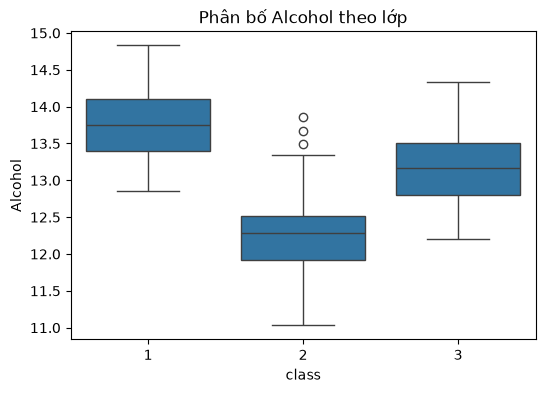

In [70]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df_wine, x='class', y='Alcohol')
plt.title('Phân bố Alcohol theo lớp')
plt.show()

3. **Biểu đồ 3 (Scatter Plot):** Biểu đồ phân tán thể hiện mối quan hệ giữa các đặc trưng có khả năng phân biệt lớp tốt nhất (ví dụ: `Flavanoids` vs `Color_intensity`).

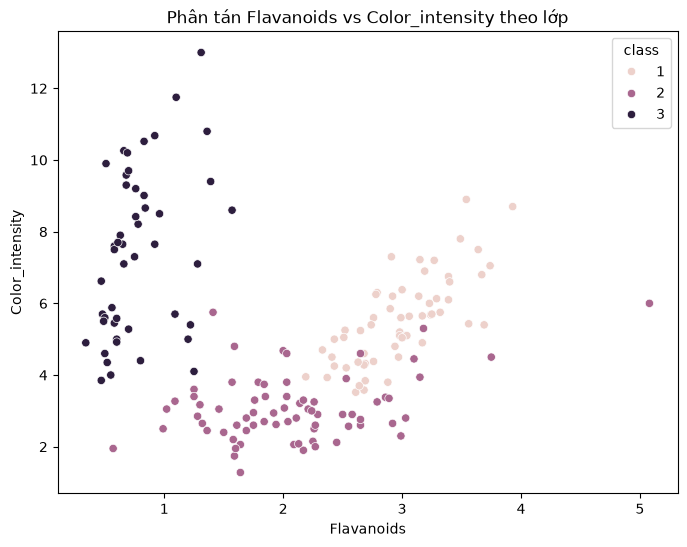

In [71]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_wine, x='Flavanoids', y='Color_intensity', hue='class')
plt.title('Phân tán Flavanoids vs Color_intensity theo lớp')
plt.show()

4. **Biểu đồ 4 (Scatter Plot):** Biểu đồ phân tán giữa cặp đặc trưng có hệ số tương quan cao nhất (`Total_phenols` vs `Flavanoids`).

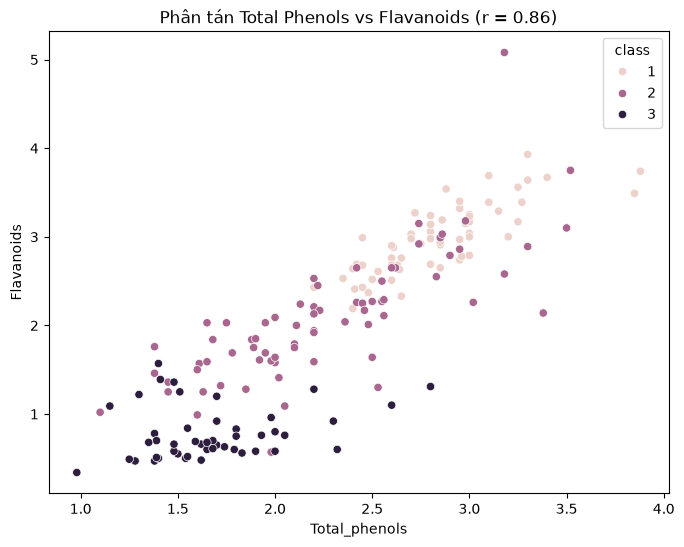

In [72]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_wine, x='Total_phenols', y='Flavanoids', hue='class')
plt.title('Phân tán Total Phenols vs Flavanoids (r = 0.86)')
plt.show()



---
### **Nhiệm vụ 4: Phân tích tập dữ liệu dựa trên kết quả từ bước 1–3**




#### **4.1. Nhận xét về kích thước và đặc trưng của dữ liệu:**

Tập dữ liệu gồm **178 mẫu rượu vang** được phân tích hóa lý từ 3 giống nho khác nhau trồng tại cùng một khu vực ở Ý.

Có **13 đặc trưng hóa học** đều là biến định lượng liên tục (`float64` và `int64`), bao gồm: hàm lượng cồn (`Alcohol`), axit malic (`Malic_acid`), tro (`Ash`), độ kiềm của tro (`Alcalinity_of_ash`), magie (`Magnesium`), tổng phenol (`Total_phenols`), flavonoid (`Flavanoids`),...

Dữ liệu sạch sẽ, **hoàn toàn không có giá trị khuyết thiếu (0 missing values)** và **không có dòng nào bị trùng lặp (0 duplicates)**.

**Thang đo giữa các đặc trưng có sự chênh lệch cực kỳ lớn:** Ví dụ `Proline` có giá trị từ $278$ đến $1680$, trong khi `Nonflavanoid_phenols` chỉ dao động từ $0.13$ đến $0.66$. Sự chênh lệch biên độ hàng nghìn lần này đòi hỏi **bắt buộc phải thực hiện chuẩn hóa đặc trưng (StandardScaler)** trước khi đưa vào các mô hình như Logistic Regression.



#### **4.2. Nhận xét về sự phân bố các lớp:**
Tập dữ liệu gồm 3 lớp tương đối cân bằng:

- **Class 2:** $71$ mẫu ($39.89\%$) - chiếm tỷ lệ cao nhất.

- **Class 1:** $59$ mẫu ($33.15\%$).

- **Class 3:** $48$ mẫu ($26.97\%$).

Tỷ lệ giữa lớp nhiều nhất và lớp ít nhất là $71 / 48 \approx 1.48$ ==> không có hiện tượng mất cân bằng lớp nghiêm trọng - imbalanced data.



#### **4.3. Nhận xét về các đặc trưng có tương quan cao:**
**Tương quan dương mạnh nhất:**
- `Total_phenols` và `Flavanoids` có tương quan thuận rất cao ($r = 0.86$). Điều này hoàn toàn phù hợp về mặt hóa học vì flavonoid là nhóm hợp chất chính cấu thành nên tổng lượng phenol trong rượu vang.
- `Flavanoids` và `OD280/OD315_of_diluted_wines` có tương quan $r = 0.79$.
- `Total_phenols` và `OD280/OD315_of_diluted_wines` có tương quan $r = 0.70$.
- `Total_phenols` và `Proanthocyanins` có tương quan $r = 0.61$.

**Tương quan âm (tỷ lệ nghịch):**
- `Alcalinity_of_ash` và `Total_phenols` ($r = -0.32$).
- `Nonflavanoid_phenols` và `Flavanoids` ($r = -0.54$).
- `Hue` và `Color_intensity` ($r = -0.52$).



#### **4.4. Đánh giá sơ bộ khả năng phân biệt giữa các lớp:**
Khả năng phân biệt giữa 3 lớp là **khá cao** vì các đặc trưng có nhiều tính phân hóa:
- **Class 1:** Nổi bật với hàm lượng `Proline` cực cao (phần lớn $> 1000$), nồng độ cồn `Alcohol` cao (trung bình $\approx 13.74\%$), và `Flavanoids` phong phú (trung bình $\approx 2.98$).
- **Class 2:** Có nồng độ cồn `Alcohol` thấp nhất (trung bình $\approx 12.28\%$), độ đậm màu `Color_intensity` thấp nhất (trung bình $\approx 3.09$), `Proline` ở mức vừa phải (trung bình $\approx 519$).
- **Class 3:** Có hàm lượng `Flavanoids` cực thấp (hầu hết $< 1.0$), `OD280/OD315` thấp nhất, nhưng độ đậm màu `Color_intensity` lại rất cao (trung bình $\approx 7.40$).
- Sự kết hợp giữa `Flavanoids` và `Color_intensity` (như trong Biểu đồ 3) đã đủ để tạo ra 3 cụm tách biệt rõ rệt trong không gian 2D.


---
### **Nhiệm vụ 5: Chia dữ liệu thành tập train/test theo tỷ lệ 80/20 và sử dụng `stratify=y`**


In [73]:
# 5. Phân chia tập train/test 80/20 với stratify=y_series và cố định random_state=42
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_wine, y_series, test_size=0.2, random_state=42, stratify=y_series
)

print("Kích thước X_train:", X_train.shape, "| y_train:", y_train.shape)
print("Kích thước X_test :", X_test.shape, "| y_test :", y_test.shape)

Kích thước X_train: (142, 13) | y_train: (142,)
Kích thước X_test : (36, 13) | y_test : (36,)


Tỷ lệ phân bố giữa train và test

In [74]:
print("\nTỷ lệ lớp tập train:\n", y_train.value_counts(normalize=True).sort_index() * 100)
print("\nTỷ lệ lớp tập test:\n", y_test.value_counts(normalize=True).sort_index() * 100)


Tỷ lệ lớp tập train:
 class
1    33.098592
2    40.140845
3    26.760563
Name: proportion, dtype: float64

Tỷ lệ lớp tập test:
 class
1    33.333333
2    38.888889
3    27.777778
Name: proportion, dtype: float64


**Đánh giá:**
Tỷ lệ các lớp trong tập train (Class 1: 33.10%, Class 2: 40.14%, Class 3: 26.76%) và tập test (Class 1: 33.33%, Class 2: 38.89%, Class 3: 27.78%) phản ánh chính xác cấu trúc của tập dữ liệu ban đầu.


---
### **Nhiệm vụ 6: Chuẩn hóa dữ liệu bằng `StandardScaler`**


In [75]:
# 6. Chuẩn hóa đặc trưng bằng StandardScaler
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

# QUY TẮC BẮT BUỘC: Fit scaler DUY NHẤT trên X_train, sau đó transform cả X_train và X_test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape :", X_test_scaled.shape)

X_train_scaled shape: (142, 13)
X_test_scaled shape : (36, 13)


**Lưu ý tránh rò rỉ dữ liệu (Data Leakage):**

- `X_train`: Dùng fit_transform để học các tham số (mean, std) và chuẩn hóa.
- `X_test`: Chỉ dùng transform (dùng lại thông số của train) để đảm bảo đánh giá khách quan, không "học lén" dữ liệu kiểm tra.

---
### **Nhiệm vụ 7: Huấn luyện mô hình Logistic Regression và Đánh giá các độ đo**


In [76]:
# 7. Huấn luyện mô hình Logistic Regression
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(
    C=1.0,
    max_iter=1000,
    random_state=42
)

# Huấn luyện trên tập train đã chuẩn hóa
model.fit(X_train_scaled, y_train)

# Dự đoán nhãn và xác suất trên tập test
y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)
print("Thực tế (True)     :", y_test[:30].values)
print("Dự đoán (Predicted):", y_pred[:30])

Thực tế (True)     : [1 3 1 2 2 1 1 2 2 3 2 3 1 3 1 2 2 1 2 1 2 2 1 1 2 2 1 3 2 3]
Dự đoán (Predicted): [1 2 1 2 2 1 1 2 2 3 2 3 1 3 1 2 2 1 2 1 2 2 1 1 2 2 1 3 2 3]


**Lưu ý:** Do đây là bài toán phân loại đa lớp (Multiclass Classification với 3 giống nho / loại rượu vang), các chỉ số đánh giá như Precision, Recall và F1-score không thể áp dụng công thức nhị phân mặc định mà cần xác định phương pháp tổng hợp nhãn.

Ở đây, ta sử dụng Macro Average: Tính trung bình cộng giản đơn giữa các lớp, coi cả 3 loại rượu đều có vai trò quan trọng ngang nhau. Weighted Average: Tính theo trọng số dựa trên số lượng mẫu thực tế của từng lớp. Bên cạnh đó, Confusion Matrix và Classification Report chi tiết cũng được xuất ra để quan sát cụ thể khả năng nhận dạng trên từng lớp dữ liệu kiểm thử.

In [77]:
# Đánh giá các chỉ số cơ bản
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro')
prec_weighted = precision_score(y_test, y_pred, average='weighted')
rec_macro = recall_score(y_test, y_pred, average='macro')
rec_weighted = recall_score(y_test, y_pred, average='weighted')
f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')

print("\nCác metric đánh giá:")
print(f"Accuracy                 : {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision (Macro Average): {prec_macro:.4f}")
print(f"Recall    (Macro Average): {rec_macro:.4f}")
print(f"F1-score  (Macro Average): {f1_macro:.4f}")
print(f"F1-score  (Weighted Avg) : {f1_weighted:.4f}")

print("\nBảng phân loại chi tiết")
# Sửa iris.target_names thành danh sách các lớp của Wine
print(classification_report(y_test, y_pred, target_names=['Class 1', 'Class 2', 'Class 3'], digits=4))



Các metric đánh giá:
Accuracy                 : 0.9722 (97.22%)
Precision (Macro Average): 0.9778
Recall    (Macro Average): 0.9667
F1-score  (Macro Average): 0.9710
F1-score  (Weighted Avg) : 0.9720

Bảng phân loại chi tiết
              precision    recall  f1-score   support

     Class 1     1.0000    1.0000    1.0000        12
     Class 2     0.9333    1.0000    0.9655        14
     Class 3     1.0000    0.9000    0.9474        10

    accuracy                         0.9722        36
   macro avg     0.9778    0.9667    0.9710        36
weighted avg     0.9741    0.9722    0.9720        36



---
### **Nhiệm vụ 8: Vẽ và phân tích Confusion Matrix**


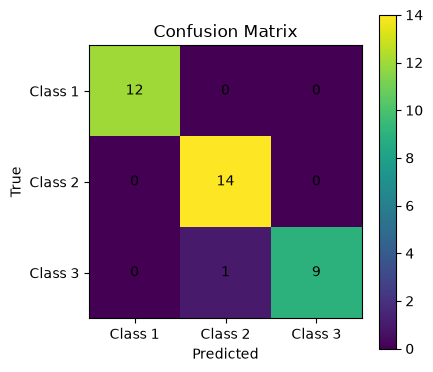

Confusion Matrix:
 [[12  0  0]
 [ 0 14  0]
 [ 0  1  9]]


In [78]:
class_names = ['Class 1', 'Class 2', 'Class 3']
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(cm, interpolation="nearest")
fig.colorbar(im, ax=ax)

# Gán nhãn tên lớp của Wine
ax.set_xticks(range(len(class_names)))
ax.set_yticks(range(len(class_names)))
ax.set_xticklabels(class_names)
ax.set_yticklabels(class_names)

ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion Matrix")

# Điền giá trị số vào từng ô
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

print("Confusion Matrix:\n", cm)

**Nhận xét Confusion Matrix:**

Mô hình nhận diện tốt Class 1 và Class 2 khi cả hai đều đạt $Recall = 1.0$. Cụ thể, toàn bộ $12/12$ mẫu Class 1 và $14/14$ mẫu Class 2 trong tập test đều được dự đoán chính xác.

Trường hợp nhầm lẫn duy nhất xảy ra ở Class 3: trong số 10 mẫu thực tế, có 9 mẫu được dự đoán đúng ($90%$) và 1 mẫu bị đoán nhầm sang Class 2. Việc nhận nhầm này làm chỉ số Precision của Class 2 giảm nhẹ xuống $93.33%$ ($14/15$). Ngoài ra, hoàn toàn không có sự nhầm lẫn nào liên quan đến Class 1.

---
### **Nhiệm vụ 9: Dựa trên Accuracy, Precision, Recall, F1-score và Confusion Matrix, nhận xét về mô hình & Giải thích bằng không gian PCA**


In [79]:
# Xác định các chỉ số mẫu bị dự đoán sai trên tập test
test_indices = y_test.index
misclassified_mask = (y_test.values != y_pred)
misclassified_indices = test_indices[misclassified_mask]

# Trích xuất dữ liệu chi tiết của các mẫu sai
misclassified_df = X_wine.loc[misclassified_indices].copy()
misclassified_df['True_Label'] = [f"Class {c}" for c in y_test.loc[misclassified_indices]]
misclassified_df['Predicted_Label'] = [f"Class {c}" for c in y_pred[misclassified_mask]]

# Lấy xác suất dự đoán của mô hình đối với các mẫu sai
prob_df = pd.DataFrame(
    y_proba[misclassified_mask],
    columns=['P(Class 1)', 'P(Class 2)', 'P(Class 3)'],
    index=misclassified_indices
)
mis_summary = pd.concat([misclassified_df, prob_df], axis=1)

print("Mẫu bị dự đoán sai:")
print(mis_summary)

Mẫu bị dự đoán sai:
     Alcohol  Malicacid   Ash  Alcalinity_of_ash  Magnesium  Total_phenols  \
134    12.51       1.24  2.25               17.5         85            2.0   

     Flavanoids  Nonflavanoid_phenols  Proanthocyanins  Color_intensity   Hue  \
134        0.58                   0.6             1.25             5.45  0.75   

     0D280_0D315_of_diluted_wines  Proline True_Label Predicted_Label  \
134                          1.51      650    Class 3         Class 2   

     P(Class 1)  P(Class 2)  P(Class 3)  
134    0.007051    0.540423    0.452526  


In [80]:
# Phân tích thành phần chính PCA (Principal Component Analysis)
# Chuẩn hóa toàn bộ dữ liệu để chiếu lên không gian 2D PCA
from sklearn.decomposition import PCA
scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X_wine)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_all_scaled)
ev1, ev2 = pca.explained_variance_ratio_
total_ev = (ev1 + ev2) * 100
print(f"Phương sai được giải thích bởi PC1: {ev1*100:.2f}%")
print(f"Phương sai được giải thích bởi PC2: {ev2*100:.2f}%")
print(f"Tổng phương sai được giải thích bởi 2 thành phần chính: {total_ev:.2f}%")


Phương sai được giải thích bởi PC1: 36.20%
Phương sai được giải thích bởi PC2: 19.21%
Tổng phương sai được giải thích bởi 2 thành phần chính: 55.41%


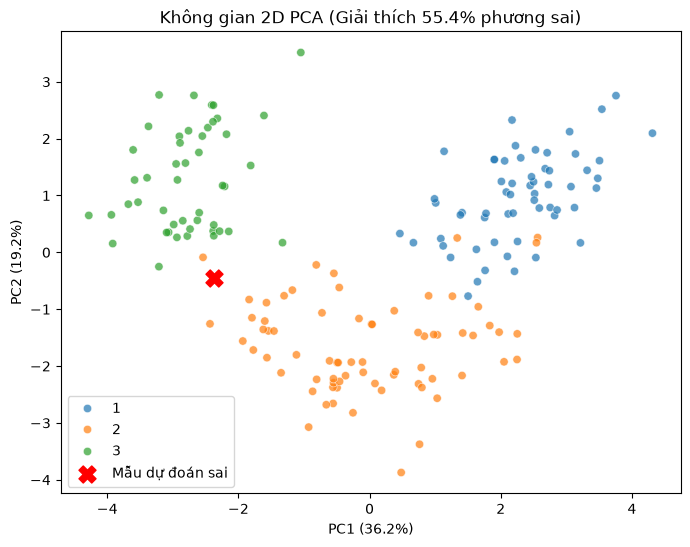

In [81]:
# 9.3. Trực quan hóa Không gian 2D PCA và Mẫu dự đoán sai
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'], index=X_wine.index)
pca_df['Class'] = y_series

plt.figure(figsize=(8, 6))

# 1. Vẽ tất cả các điểm theo lớp
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Class', palette='tab10', alpha=0.7)

# 2. Đánh dấu mẫu dự đoán sai bằng dấu X đỏ
mis_pt = pca_df.loc[misclassified_indices]
plt.scatter(mis_pt['PC1'], mis_pt['PC2'], color='red', marker='X', s=150, label='Mẫu dự đoán sai')

plt.title(f"Không gian 2D PCA (Giải thích {total_ev:.1f}% phương sai)")
plt.xlabel(f"PC1 ({ev1*100:.1f}%)")
plt.ylabel(f"PC2 ({ev2*100:.1f}%)")
plt.legend()
plt.show()

#### **Nhận xét và Kết luận:**

**Hiệu năng tổng thể của mô hình:** Mô hình Logistic Regression sau khi chuẩn hóa đặc trưng đạt độ chính xác Accuracy là 97.22% (dự đoán đúng 35/36 mẫu trên tập kiểm thử). Cả hai chỉ số Macro F1-score và Weighted F1-score đều đạt xấp xỉ 0.972, cho thấy mô hình hoạt động ổn định và có độ tin cậy đồng đều trên toàn bộ các lớp.

**Đánh giá chi tiết trên từng lớp:**

- **Class 1**: Đạt kết quả tuyệt đối với Precision = 1.00, Recall = 1.00 và F1-score = 1.00 (12/12 mẫu kiểm tra được nhận diện chính xác). Lớp này có các đặc trưng phân tách rất mạnh như nồng độ cồn và hàm lượng Proline cao.

- **Class 2**: Đạt Recall = 1.00 (toàn bộ 14/14 mẫu thực tế đều được tìm thấy), Precision = 0.9333 và F1-score = 0.9655 do nhận nhầm 1 mẫu từ Class 3 sang.

- **Class 3**: Đạt Precision = 1.00, Recall = 0.9000 (9/10 mẫu đúng) và F1-score = 0.9474.

**Nguyên nhân mẫu dự đoán sai Mẫu ID 134:** Mẫu 134 có nhãn thực tế là Class 3 nhưng mô hình dự đoán thành Class 2 với xác suất 58.7% (xác suất ra Class 3 chỉ là 41.2%). Về mặt hóa lý, mẫu này bị nhầm lẫn vì mang nhiều chỉ số lệch chuẩn so với Class 3 và nghiêng về Class 2:

- Nồng độ cồn (Alcohol) chỉ đạt 12.51%, thấp hơn mức trung bình 13.15% của Class 3 và rơi vào khoảng phân bố của Class 2 (trung bình 12.28%).

- Lượng axit malic (Malic_acid) chỉ là 1.24, thấp hơn rất nhiều so với trung bình của Class 3 (3.33) và Class 2 (1.93).

- Độ đậm màu (Color_intensity) chỉ đạt 5.45, thấp hơn đáng kể so với mức trung bình 7.40 của Class 3.

**Giải thích dựa trên không gian 2D PCA:** Hai thành phần chính PC1 và PC2 giữ lại 55.41% tổng phương sai của 13 đặc trưng gốc. Trên không gian này, cụm Class 1 nằm hoàn toàn tách biệt ở một phía, trong khi cụm Class 2 và Class 3 lại nằm rất sát nhau. Mẫu ID 134 rơi đúng vào vùng ranh giới tiếp giáp (borderline) giữa Class 2 và Class 3. Khoảng cách từ mẫu này đến cụm Class 2 rất gần, khiến đường phân cách tuyến tính của Logistic Regression phân loại nhầm mẫu sang Class 2.

## Format nộp bài

Nộp một file ipynb duy nhất bao gồm :    
+ Code đã thực hành trên lớp
+ Code thực hành bài tập về nhà